In [157]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from datetime import datetime
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [158]:
def reload_df():
    df = pd.read_csv("MavenRail.csv")
    df.dropna(inplace=True, subset=["Scheduled.Arrival", "Departure"]) # These can't be null, only one case where they are though
    df["Departure"] = pd.to_datetime(df["Departure"])
    df["Scheduled.Arrival"] = pd.to_datetime(df["Scheduled.Arrival"])
    df["Actual.Arrival"] = pd.to_datetime(df["Actual.Arrival"])
    df["Journey.Len"] = df["Scheduled.Arrival"] - df["Departure"]
    df["Delay.Len"] = df["Actual.Arrival"] - df["Scheduled.Arrival"]
    df["ToD.Departure"] = hoursPastMidnight(df["Departure"])
    df["TimeFromMidday"] = (df["ToD.Departure"] - 12)/12
    df["MorningRushHour"] = df["ToD.Departure"].apply(lambda x: 1 if x<10 and x>6.5 else 0) # Assumes still rush on weekends
    df["PeakHours"] = df["ToD.Departure"].apply(lambda x: 1 if x>6 and x<10 or x>17 and x<19 else 0)
    df["Refund.Request"] = df["Refund.Request"].apply(lambda x: 1 if x=="Yes" else 0)
    df["Railcard"] = df["Railcard"].fillna("No railcard")
    df["Railcard2"] = df["Railcard"].apply(lambda x: "SeniorOrDisabled" if x in ("Senior","Disabled") else x) # grouping because disabled railcard leads to separation
    df_late = df[df["Journey.Status"]!="On Time"]
    return df_late

def build_df_late(df_late):
    # Make new dummy vars (for when not comparing across all categories of a variable):
    df_late["UsedDebitCard"] = (df_late["Payment.Method"]=="Debit Card").astype(int)
    df_late["UsedDisabledRailcard"] = (df_late["Railcard"]=="Disabled").astype(int)
    df_late["MissingRailcardValue"] = (df_late["Railcard"].isnull()).astype(int)
    df_late["DelayedNotCancelled"] = (df_late["Journey.Status"]=="Delayed").astype(int)
    df_late["ReasonWeather"] = (df_late["Reason.for.Delay"]=="Weather").astype(int)

    # Make timedeltas into minutes, maybe log because it seems long-tailed with lots of small values
    df_late["Journey.Len"] = df_late["Journey.Len"].apply(lambda x: x.total_seconds()/60)
    df_late["Delay.Len"] = df_late["Delay.Len"].apply(lambda x: x.total_seconds()/60)

    # Use log(Price)
    df_late["Price"] = np.log(df_late["Price"])
    df_late["Price/Hour"] = df_late["Price"]/(df_late["Journey.Len"]/60)

    # !!! Delay.Len will be NaN when a journey is cancelled, DelayedNotCancelled==0 !!!
    # So any dropna() will remove all cancelled journeys, better to find a filler value
    # For now using 0, so a multi-level anaylsis split over DelayedNotCancelled will learn not to use Delay.Len when DelayedNotCancelled==0
    df_late["Delay.Len"] = df_late["Delay.Len"].fillna(0)
    df_late["DelayRatio"] = df_late["Delay.Len"]/df_late["Journey.Len"]

    ### comparing over time bands:
    ### we can separate into <=0, <=15, <=30, <=60, 60+
    def time_bins(x, bins=[0, 15, 30, 60]):
        # bins must be in ascending order
        for limit in bins:
            if x<= limit:
                return "<=" + str(limit)
        return "+" + str(max(bins))
    
    df_late["DelayBin"] = df_late["Delay.Len"].apply(time_bins)
    df_late["ToDBins"] = df_late["ToD.Departure"].apply(lambda x: time_bins(x, bins=[7,11,14,18,24]))

    def is_medium_price(value, lowbound=10, highbound=30):
        return 1 if lowbound<value and value<=highbound else 0
    df["MediumPrice"] = df["Price"].apply(lambda x: is_medium_price(x))
    
    df["Refund.Request"] = df["Refund.Request"].apply(lambda x: 1 if x=="Yes" else 0)
    return df_late

def refresh_df_late():
    return build_df_late(reload_df())

In [159]:
df = pd.read_csv("MavenRail.csv")

### Parse datetime strings as datetime, derive Delay.Len and Journey.Len:

In [160]:
df["Departure"] = pd.to_datetime(df["Departure"])
df["Scheduled.Arrival"] = pd.to_datetime(df["Scheduled.Arrival"])
df["Actual.Arrival"] = pd.to_datetime(df["Actual.Arrival"])

df["Journey.Len"] = df["Scheduled.Arrival"] - df["Departure"]
df["Delay.Len"] = df["Actual.Arrival"] - df["Scheduled.Arrival"]

In [161]:
## Also can derive time of day (from HandlingDates_2026_Python.ipynb):
def hoursPastMidnight( datetime_series ):
    dt_at_midnight = datetime_series.dt.floor('D') # Gets datetime64's, with H:M:S set to 0's
    td_series = (datetime_series - dt_at_midnight) # Produces a series of timedelta64 objects
    hours_after_midnight = td_series.dt.total_seconds() / 3600 # Get time difference in hours
    return( hours_after_midnight )
df["ToD.Departure"] = hoursPastMidnight(df["Departure"])

In [162]:
# Only looking at late journeys
df_late = df[df["Journey.Status"]!="On Time"]

# Make timedeltas into minutes, maybe log because it seems long-tailed with lots of small values
df_late["Journey.Len"] = df_late["Journey.Len"].apply(lambda x: x.total_seconds()/60)
df_late["Delay.Len"] = df_late["Delay.Len"].apply(lambda x: x.total_seconds()/60)

### Create MediumPrice as in Q3:

In [163]:
def is_medium_price(value, lowbound=10, highbound=30):
    return 1 if lowbound<value and value<=highbound else 0

df_late["MediumPrice"] = df_late["Price"].apply(lambda x: is_medium_price(x))
df_late["Refund.Request"] = df_late["Refund.Request"].apply(lambda x: 1 if x=="Yes" else 0)

### Exploring relationships between variables:

In [164]:
numeric_cols = ['Price', 'Departure', 'Scheduled.Arrival', 'Actual.Arrival',
       'Refund.Request', 'Journey.Len', 'Delay.Len',
       'ToD.Departure', 'MediumPrice']
cat_cols = ['Payment.Method', 'Railcard', 'Ticket.Class', 'Ticket.Type',
       'Departure.Station', 'Arrival.Station', 'Journey.Status',
       'Reason.for.Delay']

<Axes: >

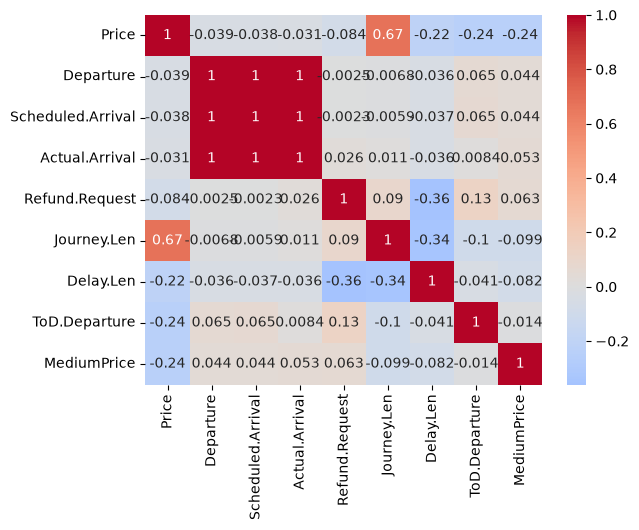

In [165]:
sns.heatmap(df_late[numeric_cols].corr(), cmap="coolwarm", center=0, annot=True)

Correlation heatmap suggests:
- Don't use Departure/Scheduled.Arrival/Actual.Arrival together, one at most - and probably not informative at all, better to derive more useful stats from them (e.g. ToD.Departure, Delay.Len)
- Price surprisingly not that much effect
- Do use: Delay.Len, ToD.Departure
- Why is Delay.Len negatively correlated with Refund.Request?? I have no idea

In [166]:
for col in cat_cols:
    print(df_late[["Refund.Request", col]].groupby(col, dropna=False).mean()\
        .merge(df_late[["Refund.Request", col]].groupby(col, dropna=False).count(), \
               on=col), "\n")

                Refund.Request_x  Refund.Request_y
Payment.Method                                    
Contactless             0.222584               921
Credit Card             0.152396              2546
Debit Card              0.767584               654 

          Refund.Request_x  Refund.Request_y
Railcard                                    
Adult             0.476678               879
Disabled          0.179811               317
Senior            0.431655               278
NaN               0.188515              2647 

              Refund.Request_x  Refund.Request_y
Ticket.Class                                    
First Class           0.273608               413
Standard              0.264833              3708 

             Refund.Request_x  Refund.Request_y
Ticket.Type                                    
Advance              0.269456              2223
Anytime              0.162162               851
Off-Peak             0.341929              1047 

                       Refund.R

Based on the categorical column info above, I would suggest:
- Debit card seems much higher, good dummy candidate
- Disabled railcard users and NaN (presumably no railcard, but can't be certain) much lower refund requests
- First Class vs Standard seem very similar, probably don't use unless interaction effects appear
- All ticket types seem fairly different from each other, only 3 types so plausible to include all
- Probably don't include departure/arrival station variables: they do have greatly varying refund request rates, but I don't see a very clear pattern and making dummy variables like "isKingsCross" seems unparsimonious
- Cancelled vs Delayed seems informative
- Lots of reasons for delay and Weather stands out as an outlier, good dummy candidate. Staff, Signal Failure, Technical Issue runners up to maybe also look at.

In [167]:
# Make new dummy vars (for when not comparing across all categories of a variable):
df_late["UsedDebitCard"] = (df_late["Payment.Method"]=="Debit Card").astype(int)
df_late["UsedDisabledRailcard"] = (df_late["Railcard"]=="Disabled").astype(int)
df_late["MissingRailcardValue"] = (df_late["Railcard"].isnull()).astype(int)
df_late["DelayedNotCancelled"] = (df_late["Journey.Status"]=="Delayed").astype(int)
df_late["ReasonWeather"] = (df_late["Reason.for.Delay"]=="Weather").astype(int)

## Testing models:

Good to have a train/validate/test split:
- let's say 90/10/0, randomly shuffled with seed=42
- Don't need a test set as we've been provided with ToPredict_with_refund.csv

In [168]:
def train_val_test_split(df, split=[0.9, 1]):
    index = list(df.index)
    np.random.seed(42)
    np.random.shuffle(index)
    cutoff = [int(split[0]*len(index)), int(split[1]*len(index))]
    train_index, val_index, test_index = index[:cutoff[0]], index[cutoff[0]:cutoff[1]], index[cutoff[1]:]
    return df.loc[train_index], df.loc[val_index], df.loc[test_index]
df_train, df_val, _ = train_val_test_split(df_late)

In [169]:
# check that proportions are quite even between train and val sets
bool_cols = ['MediumPrice', 'UsedDebitCard', 'UsedDisabledRailcard',
       'MissingRailcardValue', 'DelayedNotCancelled', 'ReasonWeather']
for dftemp in [df_train, df_val]:
    print(f"Len: {len(dftemp)}", \
          dftemp[bool_cols+['Refund.Request']].groupby("Refund.Request").mean(), \
          "\n\n")

Len: 3708                 MediumPrice  UsedDebitCard  UsedDisabledRailcard  \
Refund.Request                                                     
0                  0.162919       0.052341              0.085514   
1                  0.218090       0.459296              0.052261   

                MissingRailcardValue  DelayedNotCancelled  ReasonWeather  
Refund.Request                                                            
0                           0.710284             0.575746       0.406930  
1                           0.453266             0.498492       0.118593   


Len: 413                 MediumPrice  UsedDebitCard  UsedDisabledRailcard  \
Refund.Request                                                     
0                  0.178914       0.031949              0.089457   
1                  0.230000       0.450000              0.050000   

                MissingRailcardValue  DelayedNotCancelled  ReasonWeather  
Refund.Request                                           

### Deriving/transforming some more features to test:

In [170]:
# Use log(Price) as histogram shows long right tail
df_late["Price"] = np.log(df_late["Price"])
df_late["Price/Hour"] = df_late["Price"]/(df_late["Journey.Len"]/60)

# Delay.Len will be NaN when a journey is cancelled
# So any dropna() will remove all cancelled journeys, better to find a filler value - using 0
df_late["Delay.Len"] = df_late["Delay.Len"].fillna(0)
df_late["DelayRatio"] = df_late["Delay.Len"]/df_late["Journey.Len"]

In [171]:
### comparing over time bands:
### we can separate into <=0, <=15, <=30, <=60, 60+
def time_bins(x, bins=[0, 15, 30, 60]):
    # bins must be in ascending order
    for limit in bins:
        if x<= limit:
            return "<=" + str(limit)
    return "+" + str(max(bins))

df_late["DelayBin"] = df_late["Delay.Len"].apply(time_bins)
df_late["ToDBins"] = df_late["ToD.Departure"].apply(lambda x: time_bins(x, bins=[7,11,14,18,24]))

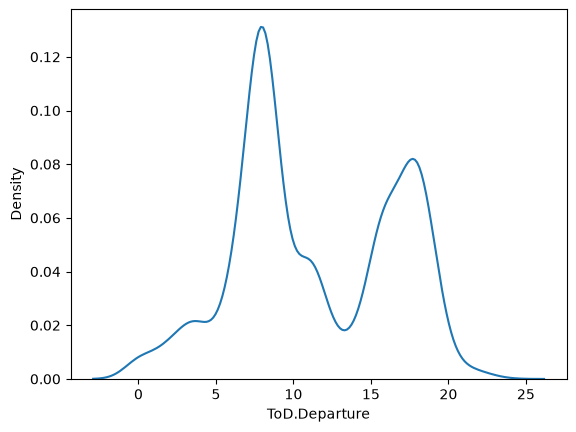

In [172]:
# Potentially useful time features:
# Informed by KDEplot of times:
sns.kdeplot(df_late["ToD.Departure"])
df_late["TimeFromMidday"] = (df_late["ToD.Departure"] - 12)/12
df_late["MorningRushHour"] = df_late["ToD.Departure"].apply(lambda x: 1 if x<10 and x>6.5 else 0) # Assumes still rush on weekends
df_late["PeakHours"] = df_late["ToD.Departure"].apply(lambda x: 1 if x>6 and x<10 or x>17 and x<19 else 0)

### Model summary to compare over performance and calibration, including splits by Status

In [173]:
def plot_model_summary(df, predictions, labels=["No Refund Request", "Refund Request"]):
    y = df["Refund.Request"]
    
    fig, axs = plt.subplots(2,2, figsize=(12,10), layout="constrained")
    axs[0,0].boxplot([predictions[y==0], predictions[y==1]], tick_labels=labels)
    
    sns.kdeplot(predictions[y==0], label=labels[0], ax=axs[0,1])
    sns.kdeplot(predictions[y==1], label=labels[1], ax=axs[0,1])
    axs[0,1].legend()
    
    mask_cancelled = df["Journey.Status"]=="Cancelled"
    mask_delayed = df["Journey.Status"]=="Delayed"
    mask_ontime = df["Journey.Status"]=="On Time"

    from sklearn.metrics import RocCurveDisplay
    from sklearn.calibration import CalibrationDisplay
    for mask in [mask_cancelled, mask_delayed, mask_cancelled|mask_delayed]:
        RocCurveDisplay.from_predictions(y[mask], predictions[mask], ax=axs[1,0])
        axs[1,0].plot([0, 1], [0, 1], "k--")
        
        CalibrationDisplay.from_predictions(y[mask], predictions[mask], ax=axs[1,1])    
    plt.show()

### Simple models with no interaction:

Optimization terminated successfully.
         Current function value: 0.376525
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:         Refund.Request   No. Observations:                 3707
Model:                          Logit   Df Residuals:                     3694
Method:                           MLE   Df Model:                           12
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.3527
Time:                        12:44:09   Log-Likelihood:                -1395.8
converged:                       True   LL-Null:                       -2156.3
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.5443        nan        nan        nan         nan         na

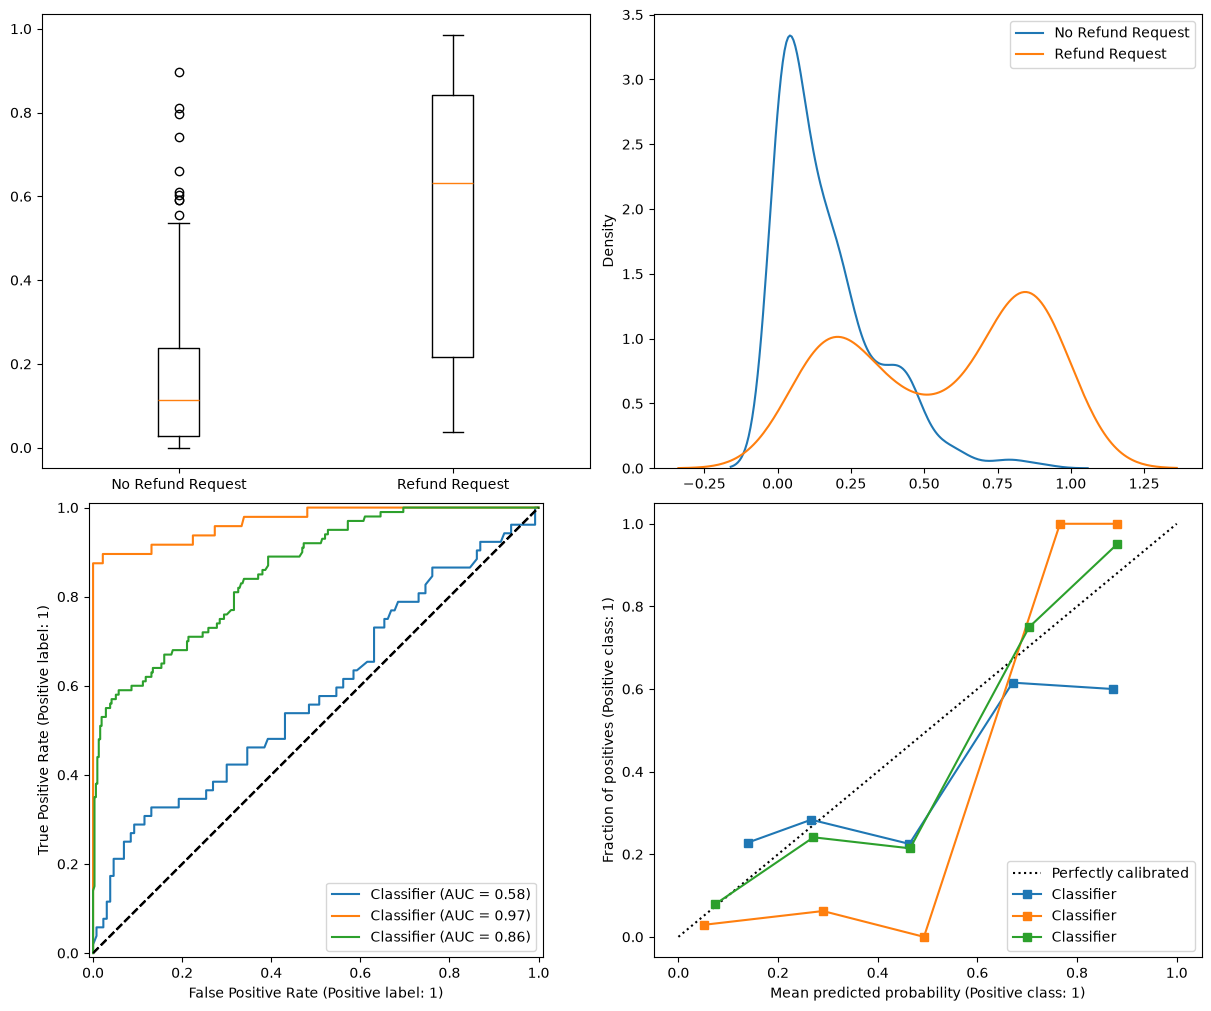

In [174]:
df_train, df_val, _ = train_val_test_split(df_late)
cols = ['Price', "Price/Hour", 'Journey.Len', 'Delay.Len', 'ToD.Departure', 'MediumPrice', 'UsedDebitCard',
       'UsedDisabledRailcard', 'ReasonWeather', 'MissingRailcardValue', "DelayedNotCancelled", "PeakHours",
       "TimeFromMidday"]
X = df_train[cols].dropna()
Y = df_train["Refund.Request"][X.index]

logreg = sm.Logit(Y, sm.add_constant(X)).fit(maxiter=100)
print(logreg.summary())

predictions = logreg.predict(sm.add_constant(df_val[cols]))
plot_model_summary(df_val, predictions)

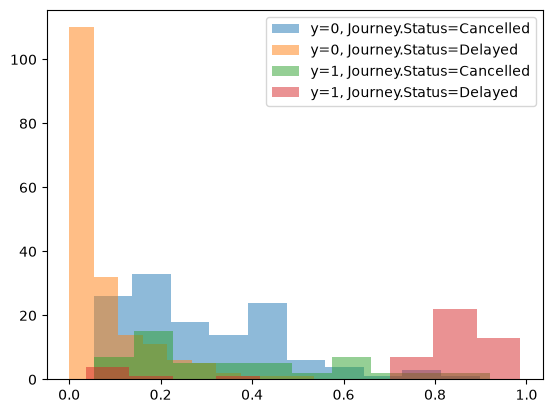

In [175]:
# Appears to be much better at Delayed journeys than Cancelled
y = df_val["Refund.Request"]
predictions = logreg.predict(sm.add_constant(df_val[cols]))

for outcome in y.unique():
    for level in df_val["Journey.Status"].unique():
        plt.hist(predictions[(y==outcome)&(df_val["Journey.Status"]==level)], 
                label=f"y={outcome}, {"Journey.Status"}={level}",
                alpha=0.5) 
plt.legend()
plt.show()

### Testing interaction effects:

In [176]:
# Make Railcard2, combining Senior+Disabled as disabled railcard leads to separation
df_late["Railcard2"] = df_late["Railcard"].fillna("No railcard")
df_late["Railcard2"] = df_late["Railcard2"].apply(lambda x: "SeniorOrDisabled" if x in ("Senior","Disabled") else x)

In [177]:
def make_interaction_formula(cols, interactor="DelayedNotCancelled"):
    cols = [f'Q("{col}")' for col in cols]
    return f'Q("Refund.Request") ~ Q("{interactor}") * ({" + ".join(cols)})'

cols = ['Price', 'Journey.Len', 
        'DelayRatio', 'ToD.Departure', 
        'MediumPrice', 'Payment.Method',
       'Railcard2', "PeakHours",
       "TimeFromMidday"]

df_train, df_val, _ = train_val_test_split(df_late)
formula = make_interaction_formula(cols, interactor="Journey.Status")
logreg = smf.logit(formula, data=df_train).fit(maxiter=100)
print(logreg.summary())

Optimization terminated successfully.
         Current function value: 0.362866
         Iterations 14
                            Logit Regression Results                           
Dep. Variable:     Q("Refund.Request")   No. Observations:                 3707
Model:                           Logit   Df Residuals:                     3684
Method:                            MLE   Df Model:                           22
Date:                 Mon, 23 Nov 2026   Pseudo R-squ.:                  0.3762
Time:                         12:44:10   Log-Likelihood:                -1345.1
converged:                        True   LL-Null:                       -2156.3
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------

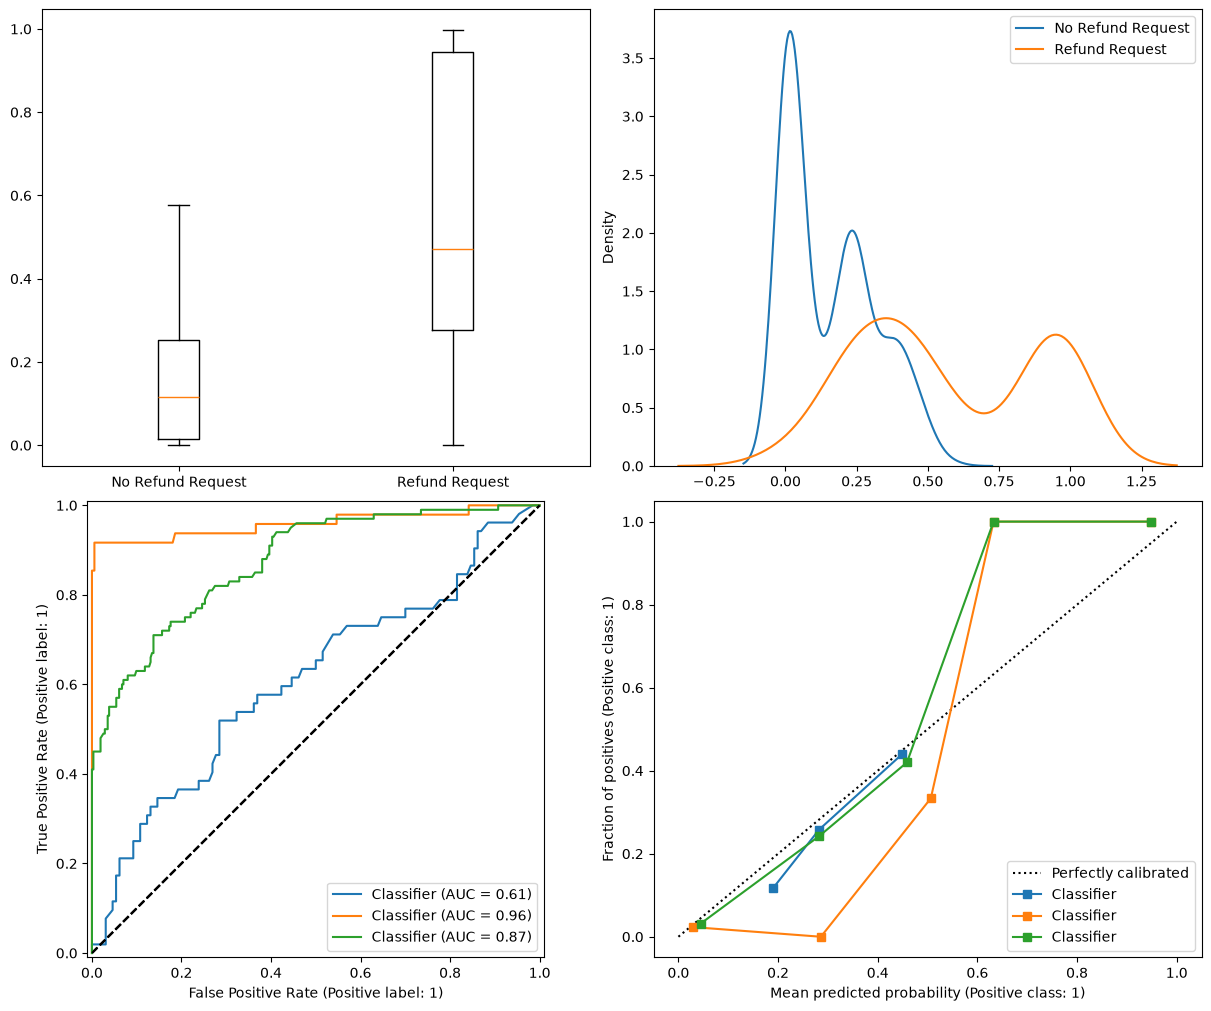

0.10539615790726863


In [178]:
# Appears to be a bit better calibrated and better discrimination
predictions = logreg.predict(df_val)
plot_model_summary(df_val, predictions)
import sklearn.metrics as sk_metrics
print(sk_metrics.brier_score_loss(df_val["Refund.Request"], predictions))

### Trying other interactions

Optimization terminated successfully.
         Current function value: 0.364170
         Iterations 12
                            Logit Regression Results                           
Dep. Variable:     Q("Refund.Request")   No. Observations:                 3707
Model:                           Logit   Df Residuals:                     3691
Method:                            MLE   Df Model:                           15
Date:                 Mon, 23 Nov 2026   Pseudo R-squ.:                  0.3739
Time:                         12:44:11   Log-Likelihood:                -1350.0
converged:                        True   LL-Null:                       -2156.3
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
Intercept            

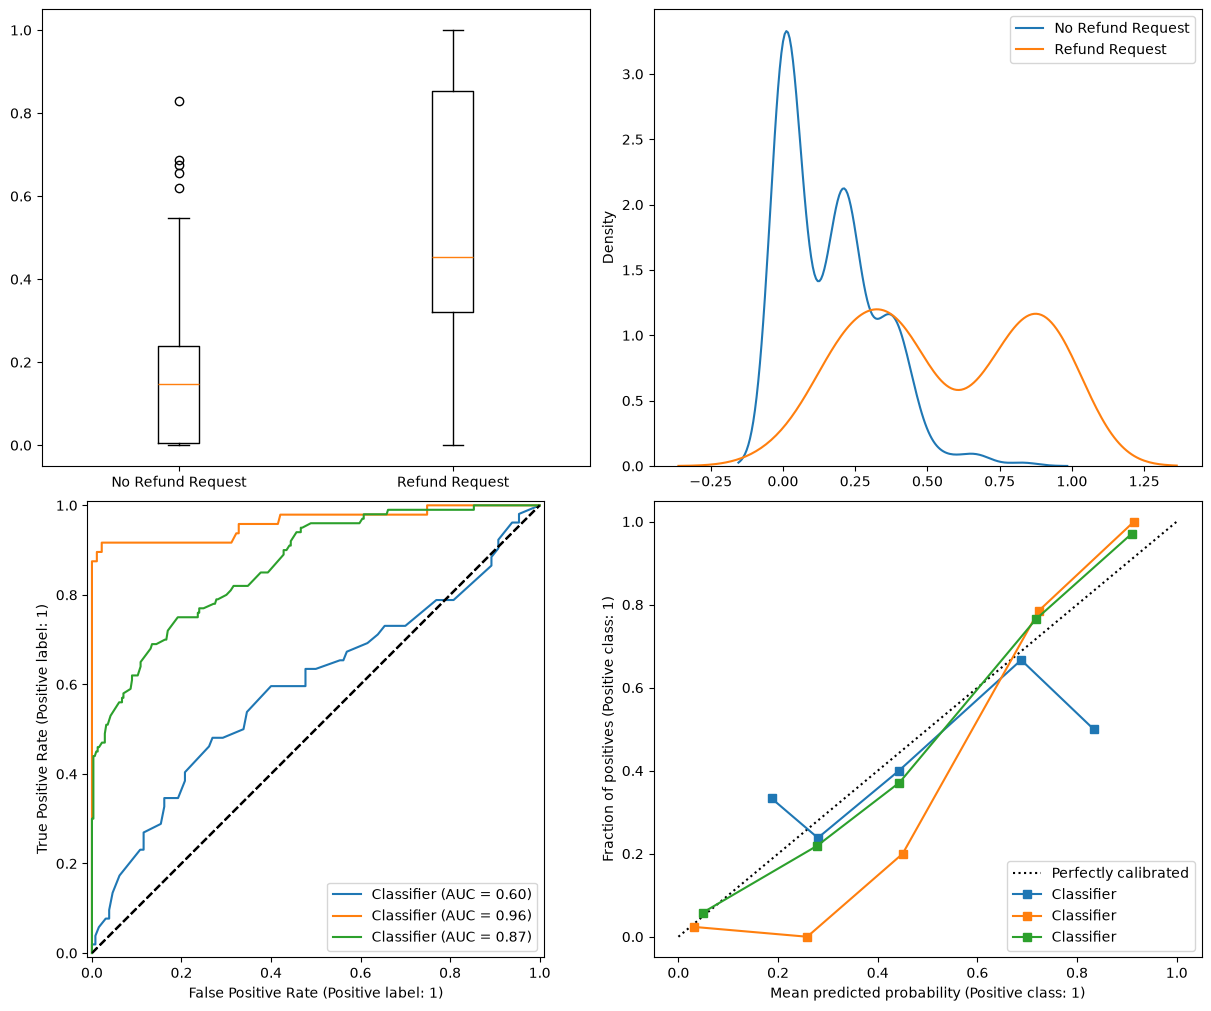

0.10859723924702602


In [179]:
df_train, df_val, _ = train_val_test_split(df_late)
formula = make_interaction_formula(cols=['Journey.Len',
                                        'DelayRatio',
                                         'Payment.Method',
                                       'Railcard2', "PeakHours"], 
                                   interactor="Delay.Len")
logreg = smf.logit(formula, data=df_train).fit(maxiter=100)
print(logreg.summary())
predictions = logreg.predict(df_val)
plot_model_summary(df_val, predictions)

print(sk_metrics.brier_score_loss(df_val["Refund.Request"], predictions))

Optimization terminated successfully.
         Current function value: 0.326096
         Iterations 10
                            Logit Regression Results                           
Dep. Variable:     Q("Refund.Request")   No. Observations:                 3707
Model:                           Logit   Df Residuals:                     3677
Method:                            MLE   Df Model:                           29
Date:                 Mon, 23 Nov 2026   Pseudo R-squ.:                  0.4394
Time:                         12:44:12   Log-Likelihood:                -1208.8
converged:                        True   LL-Null:                       -2156.3
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------

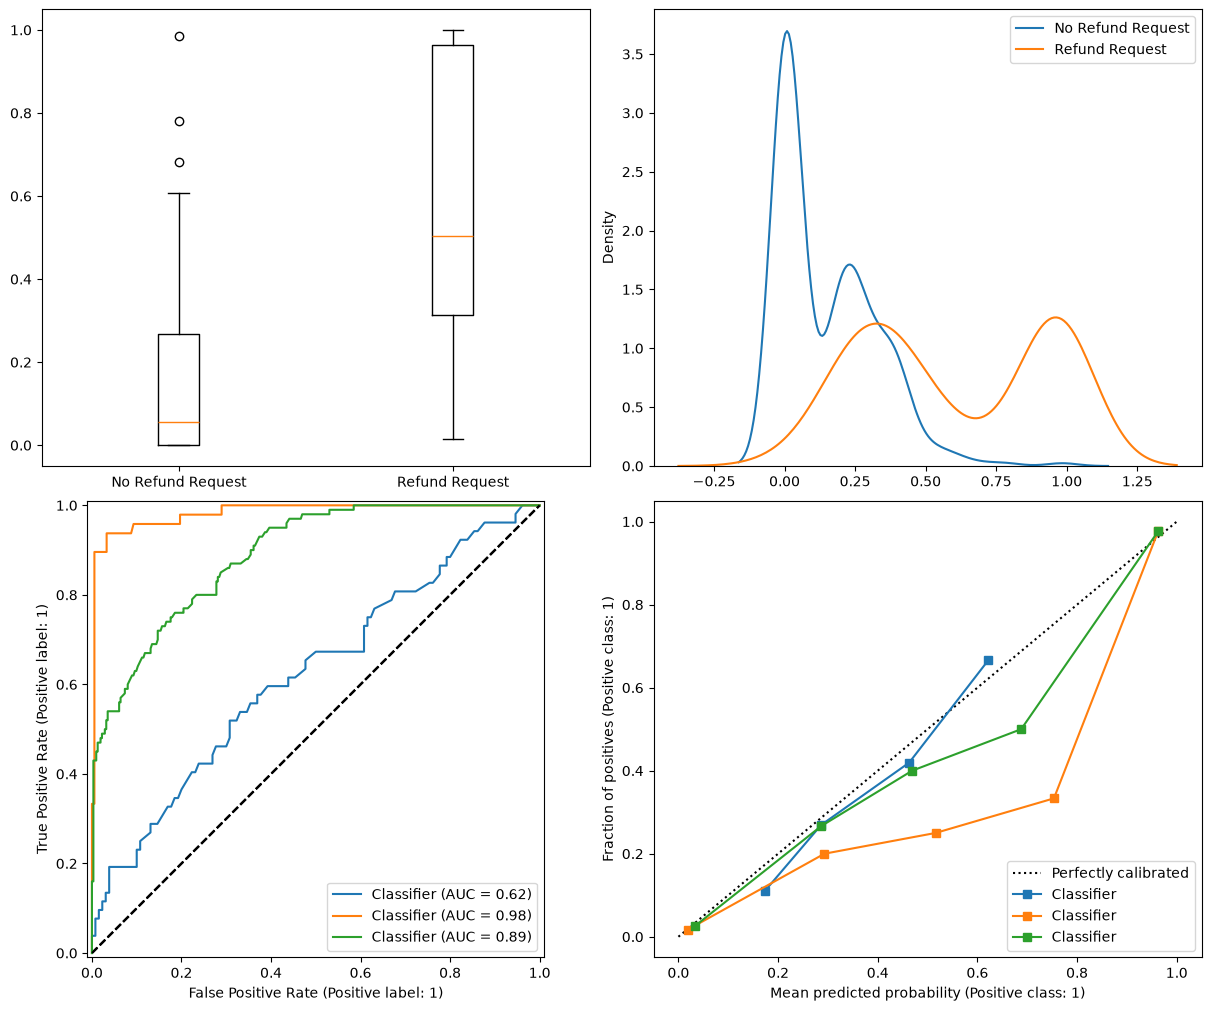

0.10214762843776976


In [180]:
# Higher order interaction doesn't seem to significantly improve, adds complexity

formula = 'Q("Refund.Request") ~ Q("Journey.Status") * (Q("Price") * ' +\
           '(Q("Journey.Len") + Q("Payment.Method") + Q("Railcard2") + Q("PeakHours"))) + ' + \
            'Q("DelayRatio") + Q("Price"):Q("DelayRatio")'

logreg = smf.logit(formula, data=df_train).fit(maxiter=100)
print(logreg.summary())
predictions = logreg.predict(df_val)
plot_model_summary(df_val, predictions)
print(sk_metrics.brier_score_loss(df_val["Refund.Request"], predictions))